# Analyzing Historical Stock/Revenue Data and Building a Dashboard

**Bandar Khashram Al-Shammari** — Final Assignment, Python Project for Data Science (IBM)

In this notebook we extract Tesla and GameStop historical stock data (via `yfinance`) and
their quarterly revenue data (via web scraping with `requests` + `BeautifulSoup`), then build
a dashboard comparing share price against revenue for each company using `plotly`.


In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import yfinance as yf
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Helper function used in Questions 5 and 6 to build the price/revenue dashboard
def make_graph(stock_data, revenue_data, stock):
    fig = make_subplots(rows=2, cols=1, shared_xaxes=False,
                         subplot_titles=(f"{stock} - Historical Share Price",
                                         f"{stock} - Historical Revenue"),
                         vertical_spacing=0.15)

    stock_data_specific = stock_data[stock_data['Date'] <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data['Date'] <= '2021-04-30']

    fig.add_trace(go.Scatter(x=pd.to_datetime(stock_data_specific['Date']),
                              y=stock_data_specific['Close'].astype('float'),
                              name='Share Price'), row=1, col=1)

    fig.add_trace(go.Scatter(x=pd.to_datetime(revenue_data_specific['Date']),
                              y=revenue_data_specific['Revenue'].astype('float'),
                              name='Revenue'), row=2, col=1)

    fig.update_xaxes(title_text='Date', row=1, col=1)
    fig.update_xaxes(title_text='Date', row=2, col=1)
    fig.update_yaxes(title_text='Price ($US)', row=1, col=1)
    fig.update_yaxes(title_text='Revenue ($US Millions)', row=2, col=1)
    fig.update_layout(showlegend=False, height=700, title_text=stock, margin=dict(t=60))
    fig.show()


## Question 1: Use yfinance to Extract Tesla Stock Data

Use the `Ticker` function to create a ticker object for Tesla (`TSLA`), then use the `history` function to extract stock information and reset the index.

In [2]:
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)
tesla_data["Date"] = tesla_data["Date"].dt.tz_localize(None)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data

Use `requests` to download the webpage and `BeautifulSoup` to parse the HTML, extracting the quarterly revenue table into a dataframe. Then clean the `Revenue` column by removing `$` and `,` characters, and drop null/blank rows.

In [3]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
html_data = requests.get(url).text
soup = BeautifulSoup(html_data, "html.parser")

tesla_revenue = pd.DataFrame(columns=["Date", "Revenue"])

for row in soup.find_all("tbody")[1].find_all("tr"):
    col = row.find_all("td")
    date = col[0].text
    revenue = col[1].text
    tesla_revenue = pd.concat(
        [tesla_revenue, pd.DataFrame({"Date": [date], "Revenue": [revenue]})],
        ignore_index=True,
    )

tesla_revenue["Revenue"] = tesla_revenue["Revenue"].str.replace(r",|\$", "", regex=True)
tesla_revenue.dropna(inplace=True)
tesla_revenue = tesla_revenue[tesla_revenue["Revenue"] != ""]
tesla_revenue.tail()

,Date,Revenue
41,2010-12-31,36
42,2010-09-30,31
43,2010-06-30,28
44,2010-03-31,21
45,2009-09-30,45


## Question 3: Use yfinance to Extract GameStop Stock Data

Repeat the same process as Question 1, but for GameStop (`GME`).

In [4]:
gamestop = yf.Ticker("GME")
gme_data = gamestop.history(period="max")
gme_data.reset_index(inplace=True)
gme_data["Date"] = gme_data["Date"].dt.tz_localize(None)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14,1.712708,1.716073,1.670626,1.683502,11021600,0.0,0.0
2,2002-02-15,1.683502,1.687209,1.658310,1.674444,8389600,0.0,0.0
3,2002-02-19,1.665385,1.665385,1.581012,1.607003,7410400,0.0,0.0
4,2002-02-20,1.615123,1.662912,1.603296,1.662912,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GameStop Revenue Data

Repeat the same scraping and cleaning process as Question 2, but for GameStop's revenue page.

In [5]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
html_data = requests.get(url).text
soup = BeautifulSoup(html_data, "html.parser")

gme_revenue = pd.DataFrame(columns=["Date", "Revenue"])

for row in soup.find_all("tbody")[1].find_all("tr"):
    col = row.find_all("td")
    date = col[0].text
    revenue = col[1].text
    gme_revenue = pd.concat(
        [gme_revenue, pd.DataFrame({"Date": [date], "Revenue": [revenue]})],
        ignore_index=True,
    )

gme_revenue["Revenue"] = gme_revenue["Revenue"].str.replace(r",|\$", "", regex=True)
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue["Revenue"] != ""]
gme_revenue.tail()

,Date,Revenue
58,2006-06-30,2040
59,2006-03-31,1469
60,2005-12-31,2104
61,2005-09-30,1552
62,2005-06-30,2032


## Question 5: Plot Tesla Stock Graph

Use the `make_graph` function to plot Tesla's historical share price against its historical revenue.

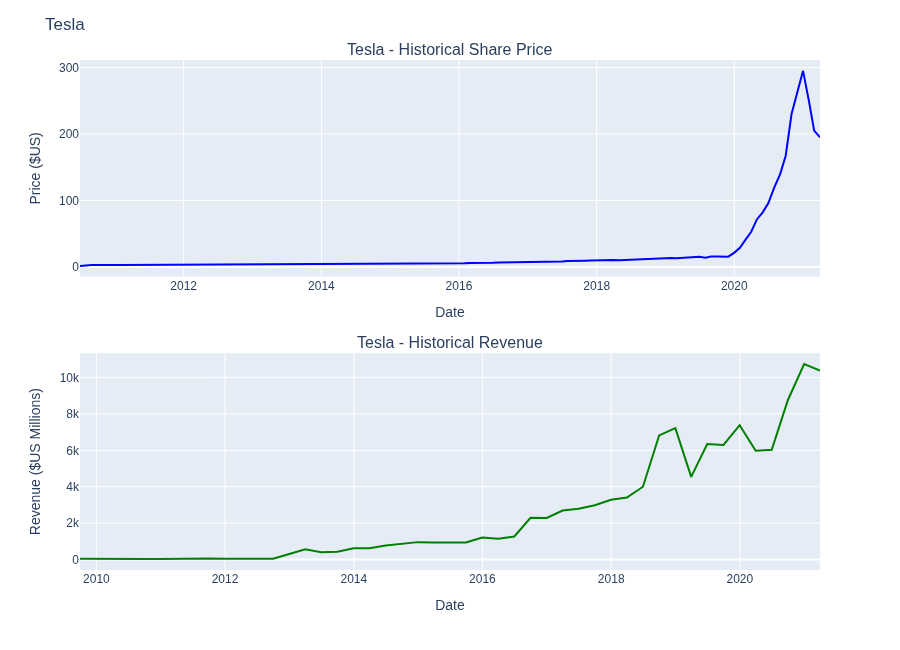

In [6]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

## Question 6: Plot GameStop Stock Graph

Use the `make_graph` function to plot GameStop's historical share price against its historical revenue.

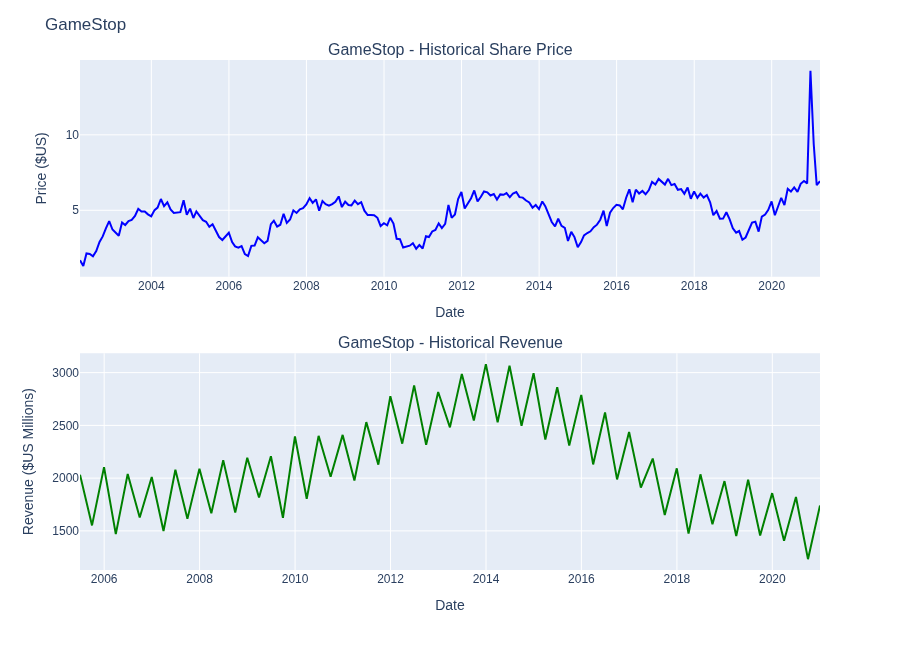

In [7]:
make_graph(gme_data, gme_revenue, 'GameStop')

## Written Questions

**Which parsers can be used in BeautifulSoup to parse HTML data?**
`html.parser` and `html5lib` (also `lxml`, not offered as an option here). `csv` and `json` are unrelated data formats, not HTML parsers.

**Why is it useful to convert the `Date` column to a datetime format in stock analysis?**
It facilitates accurate plotting of time-series data — datetime objects sort correctly, support date-range filtering/resampling, and are placed correctly along a time axis when charted, unlike plain strings.

**Correct way to remove the `$` symbol and commas from a `Price` column:**
```python
df["Price"] = df["Price"].str.replace(',|\$', "", regex=True)
```
`.apply(float)` fails on `"$1,200.50"`; `.map(lambda x: x.strip("$,"))` only strips characters from the *ends* of the string, not commas in the middle; `.replace("$,", "")` looks for the literal substring `"$,"`, which never occurs.

**Tesla's stock price and revenue trend between 2018 and 2021:**
Both Tesla's revenue and stock price showed strong growth — revenue climbed steadily from about $3.4B to over $10B/quarter, while the share price rose from roughly $20 to a peak near $295 in early 2021.

**Key observation about GameStop's stock price and revenue:**
Stock price surged sharply around 2021 (the short-squeeze episode), but revenue did not show a similar increase — GameStop's quarterly revenue continued its normal seasonal (holiday-quarter) pattern and was actually trending down, showing the price spike was driven by trading activity rather than business fundamentals.
